<a href="https://colab.research.google.com/github/thousand8974-07/likelion-mju-ai/blob/thousand8974-07/DiffusionPolicy_PushT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diffusion Policy 처음부터 구현하기: Push-T (state 기반)

**목표**: 사람이 마우스로 T자 블록을 목표 위치로 밀어 넣은 시연 데이터(Push-T)를 보고,
로봇이 같은 일을 하도록 **Diffusion Policy**를 직접 구현·학습·평가한다.

**전체 흐름**
1. 데이터 불러오기 → 2. 학습용 샘플 만들기(관측 2스텝 → 행동 16스텝) → 3. 노이즈 예측 모델(1D U-Net) →
4. DDPM 학습 → 5. 노이즈에서 행동 생성(디노이징) → 6. 시뮬레이터에서 실제로 밀어보기

**런타임 설정**: 상단 메뉴 `런타임 → 런타임 유형 변경 → T4 GPU` 선택 후 실행하세요.

> 원 논문: Chi et al., *Diffusion Policy: Visuomotor Policy Learning via Action Diffusion* (RSS 2023)

## 0. 설치

In [1]:
!pip install -q gym-pusht "zarr<3" diffusers gdown mediapy

In [2]:
import os, math, copy, collections
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

torch.manual_seed(0)
np.random.seed(0)

device: cuda


## 1. 데이터 불러오기

Diffusion Policy 저자들이 공개한 Push-T 시연 데이터(zarr 형식)를 받습니다.

| 키 | 모양 | 의미 |
|---|---|---|
| `data/state` | (N, 5) | 관측: 에이전트 x, y / 블록 x, y / 블록 각도 |
| `data/action` | (N, 2) | 행동: 에이전트가 이동할 목표 위치 x, y (0~512 좌표) |
| `meta/episode_ends` | (에피소드 수,) | 각 에피소드가 끝나는 인덱스 |

> Google Drive 다운로드가 "too many users" 오류로 막히면 잠시 후 다시 실행하세요.

In [3]:
import gdown, zarr

DATA_PATH = "pusht_cchi_v7_replay.zarr.zip"
if not os.path.isfile(DATA_PATH):
    gdown.download(id="1KY1InLurpMvJDRb14L9NlXT_fEsCvVUq", output=DATA_PATH, quiet=False)

root = zarr.open(DATA_PATH, mode="r") #큰 배열 저장하는 파일 지정 형식
states  = root["data"]["state"][:].astype(np.float32)    # (N, 5)
actions = root["data"]["action"][:].astype(np.float32)   # (N, 2)
episode_ends = root["meta"]["episode_ends"][:]           # (E,)

print("states :", states.shape)
print("actions:", actions.shape)
print("에피소드 수:", len(episode_ends))
ep_lens = np.diff(np.concatenate([[0], episode_ends]))
print(f"에피소드 길이: 평균 {ep_lens.mean():.0f}, 최소 {ep_lens.min()}, 최대 {ep_lens.max()}")

Downloading...
From (original): https://drive.google.com/uc?id=1KY1InLurpMvJDRb14L9NlXT_fEsCvVUq
From (redirected): https://drive.google.com/uc?id=1KY1InLurpMvJDRb14L9NlXT_fEsCvVUq&confirm=t&uuid=2672b5bf-ad9f-4460-bdef-1d96cf5404a5
To: /content/pusht_cchi_v7_replay.zarr.zip
100%|██████████| 31.1M/31.1M [00:00<00:00, 128MB/s]


states : (25650, 5)
actions: (25650, 2)
에피소드 수: 206
에피소드 길이: 평균 125, 최소 49, 최대 246


에피소드 몇 개의 행동 궤적을 그려 보면, 같은 과제라도 사람마다 미는 경로가 다르다는 것(= **멀티모달리티**)을 볼 수 있습니다.

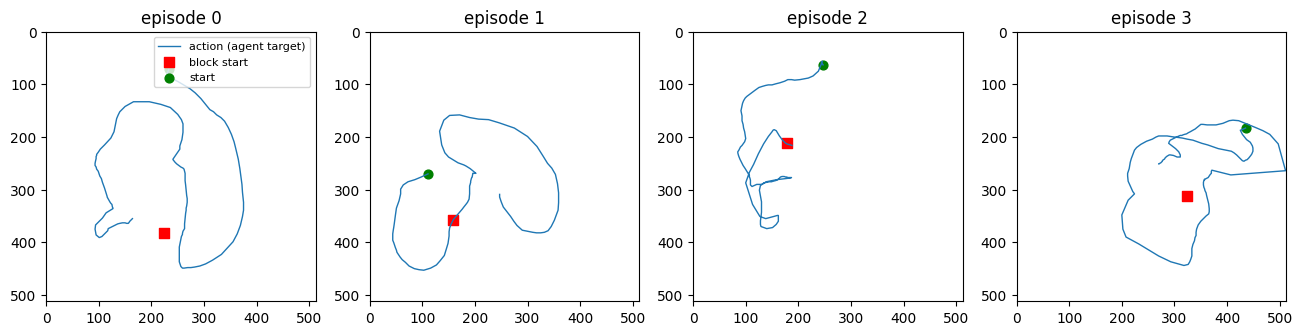

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, ep in zip(axes, [0, 1, 2, 3]):
    s = 0 if ep == 0 else episode_ends[ep - 1]
    e = episode_ends[ep]
    a = actions[s:e]
    ax.plot(a[:, 0], a[:, 1], "-", lw=1, label="action (agent target)")
    ax.scatter(*states[s, 2:4], c="red", s=60, marker="s", label="block start")
    ax.scatter(*a[0], c="green", s=40, label="start")
    ax.set_xlim(0, 512); ax.set_ylim(512, 0)   # 화면 좌표계(y 아래로 증가)
    ax.set_aspect("equal"); ax.set_title(f"episode {ep}")
axes[0].legend(fontsize=8)
plt.show()

## 2. 학습용 샘플 만들기

Diffusion Policy의 핵심 설정 세 가지:

- **obs_horizon = 2**: 최근 관측 2스텝을 보고
- **pred_horizon = 16**: 앞으로의 행동 16스텝을 *한 번에* 예측하고
- **action_horizon = 8**: 그중 8스텝만 실제로 실행한 뒤 다시 예측 (receding horizon)

```
시간축:   t-1   t   t+1 ... t+14
관측:     [o]  [o]
예측:     [a]  [a]  [a] ... [a]        ← 16개 (pred_horizon)
실행:          [a]  [a] ... [a]        ← 8개 (action_horizon), 인덱스 1~8
```

에피소드 경계를 넘어가는 부분은 **첫/마지막 값을 반복(padding)** 해서 채웁니다.
또한 디퓨전 모델은 입력 범위가 [-1, 1]일 때 잘 동작하므로 **min-max 정규화**를 합니다.

In [5]:
OBS_HORIZON = 2  # 9장 타임라인 // 행동을 묶어서 예측
PRED_HORIZON = 16
ACTION_HORIZON = 8
OBS_DIM = states.shape[1]     # 5
ACTION_DIM = actions.shape[1] # 2

def get_stats(x):
    return {"min": x.min(axis=0), "max": x.max(axis=0)}

def normalize(x, stats):
    x = (x - stats["min"]) / (stats["max"] - stats["min"] + 1e-8)  # [0, 1]
    return x * 2 - 1                                                # [-1, 1]

def unnormalize(x, stats):
    x = (x + 1) / 2
    return x * (stats["max"] - stats["min"] + 1e-8) + stats["min"]

stats = {"state": get_stats(states), "action": get_stats(actions)}
norm_states = normalize(states, stats["state"])
norm_actions = normalize(actions, stats["action"])


class PushTDataset(torch.utils.data.Dataset):
    def __init__(self, norm_states, norm_actions, episode_ends):
        self.S, self.A = norm_states, norm_actions
        # (에피소드 시작, 끝, 현재 시점 t) 목록을 미리 만들어 둔다
        self.items = []
        start = 0
        for end in episode_ends:
            for t in range(start, end):
                self.items.append((start, end, t))
            start = end

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        start, end, t = self.items[i]
        # 관측: t-1, t  (에피소드 시작 이전이면 시작값으로 패딩)
        obs_idx = np.arange(t - OBS_HORIZON + 1, t + 1)
        obs_idx = np.clip(obs_idx, start, end - 1)
        # 행동: t-1 부터 16스텝 (에피소드 끝을 넘으면 마지막 값으로 패딩)
        act_idx = np.arange(t - OBS_HORIZON + 1, t - OBS_HORIZON + 1 + PRED_HORIZON)
        act_idx = np.clip(act_idx, start, end - 1)
        return {
            "obs": torch.from_numpy(self.S[obs_idx]),     # (2, 5)
            "action": torch.from_numpy(self.A[act_idx]),  # (16, 2)
        }

dataset = PushTDataset(norm_states, norm_actions, episode_ends)
dataloader = torch.utils.data.DataLoader(
    dataset, batch_size=256, shuffle=True, num_workers=2, drop_last=True, pin_memory=True
)

batch = next(iter(dataloader))
print("샘플 수:", len(dataset))
print("obs   :", batch["obs"].shape)     # (B, 2, 5)
print("action:", batch["action"].shape)  # (B, 16, 2)

샘플 수: 25650
obs   : torch.Size([256, 2, 5])
action: torch.Size([256, 16, 2])


## 3. 노이즈 예측 모델: Conditional 1D U-Net

디퓨전 모델이 학습하는 것은 **"노이즈 섞인 행동 시퀀스에서 노이즈가 얼마나 섞였는지"** 입니다.
행동 시퀀스라 1D , 이미지는 2D

- 입력: 노이즈 섞인 행동 시퀀스 `(B, 16, 2)` + 디퓨전 스텝 `k` + 관측(조건) `(B, 2×5)`
- 출력: 예측한 노이즈 `(B, 16, 2)`

행동 시퀀스를 **시간축 방향의 1D 신호**로 보고 1D 합성곱 U-Net으로 처리합니다.
관측과 스텝 정보는 **FiLM**(채널마다 `scale * x + bias`) 방식으로 각 블록에 주입합니다.

In [6]:
class SinusoidalPosEmb(nn.Module):
    """디퓨전 스텝 k(정수)를 벡터로 바꾸는 임베딩 (Transformer 위치 임베딩과 같은 방식)"""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, k):
        half = self.dim // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=k.device) / (half - 1))
        emb = k.float()[:, None] * freqs[None, :]
        return torch.cat([emb.sin(), emb.cos()], dim=-1)


class Conv1dBlock(nn.Module):
    """Conv1d → GroupNorm → Mish"""
    def __init__(self, in_ch, out_ch, kernel_size=5, n_groups=8):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv1d(in_ch, out_ch, kernel_size, padding=kernel_size // 2),
            nn.GroupNorm(n_groups, out_ch),
            nn.Mish(),
        )

    def forward(self, x):
        return self.block(x)


class CondResBlock1D(nn.Module):
    """조건(cond)을 FiLM으로 주입하는 residual 블록"""
    def __init__(self, in_ch, out_ch, cond_dim):
        super().__init__()
        self.conv1 = Conv1dBlock(in_ch, out_ch)
        self.conv2 = Conv1dBlock(out_ch, out_ch)
        # cond → 채널별 scale, bias
        self.film = nn.Sequential(nn.Mish(), nn.Linear(cond_dim, out_ch * 2))
        self.residual = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, cond):
        # x: (B, C_in, T), cond: (B, cond_dim)
        h = self.conv1(x)
        scale, bias = self.film(cond).unsqueeze(-1).chunk(2, dim=1)  # 각각 (B, C_out, 1)
        h = scale * h + bias
        h = self.conv2(h)
        return h + self.residual(x)


class ConditionalUnet1D(nn.Module):
    def __init__(self, action_dim, global_cond_dim, step_emb_dim=256, down_dims=(256, 512, 1024)):
        super().__init__()
        self.step_encoder = nn.Sequential(
            SinusoidalPosEmb(step_emb_dim),
            nn.Linear(step_emb_dim, step_emb_dim * 4), nn.Mish(),
            nn.Linear(step_emb_dim * 4, step_emb_dim),
        )
        cond_dim = step_emb_dim + global_cond_dim
        dims = [action_dim] + list(down_dims)
        in_out = list(zip(dims[:-1], dims[1:]))   # [(2,256), (256,512), (512,1024)]

        # 내려가는 길: 해상도 16 → 8 → 4
        self.downs = nn.ModuleList()
        for i, (d_in, d_out) in enumerate(in_out):
            is_last = i == len(in_out) - 1
            self.downs.append(nn.ModuleList([
                CondResBlock1D(d_in, d_out, cond_dim),
                CondResBlock1D(d_out, d_out, cond_dim),
                nn.Conv1d(d_out, d_out, 3, stride=2, padding=1) if not is_last else nn.Identity(),
            ]))

        mid = down_dims[-1]
        self.mids = nn.ModuleList([
            CondResBlock1D(mid, mid, cond_dim),
            CondResBlock1D(mid, mid, cond_dim),
        ])

        # 올라가는 길: 해상도 4 → 8 → 16
        # skip connection을 이어붙이므로 입력 채널이 2배
        self.ups = nn.ModuleList()
        for d_in, d_out in reversed(in_out[1:]):
            self.ups.append(nn.ModuleList([
                CondResBlock1D(d_out * 2, d_in, cond_dim),
                CondResBlock1D(d_in, d_in, cond_dim),
                nn.ConvTranspose1d(d_in, d_in, 4, stride=2, padding=1),
            ]))

        self.final = nn.Sequential(
            Conv1dBlock(down_dims[0], down_dims[0]),
            nn.Conv1d(down_dims[0], action_dim, 1),
        )

    def forward(self, x, k, global_cond):
        # x: (B, T, action_dim)  k: (B,) 또는 정수  global_cond: (B, global_cond_dim)
        x = x.transpose(1, 2)  # (B, action_dim, T)  ← 시간축을 Conv1d의 길이 축으로
        if not torch.is_tensor(k):
            k = torch.tensor([k], device=x.device)
        k = k.to(x.device).reshape(-1).expand(x.shape[0])
        cond = torch.cat([self.step_encoder(k), global_cond], dim=-1)

        skips = []
        for res1, res2, down in self.downs:
            x = res2(res1(x, cond), cond)
            skips.append(x)
            x = down(x)
        for res in self.mids:
            x = res(x, cond)
        for res1, res2, up in self.ups:
            x = torch.cat([x, skips.pop()], dim=1)
            x = res2(res1(x, cond), cond)
            x = up(x)
        x = self.final(x)
        return x.transpose(1, 2)  # (B, T, action_dim)


model = ConditionalUnet1D(action_dim=ACTION_DIM, global_cond_dim=OBS_DIM * OBS_HORIZON).to(device)
print(f"파라미터 수: {sum(p.numel() for p in model.parameters()) / 1e6:.1f}M")

# 모양 확인
with torch.no_grad():
    out = model(torch.randn(4, PRED_HORIZON, ACTION_DIM, device=device),
                torch.zeros(4, dtype=torch.long, device=device),
                torch.randn(4, OBS_DIM * OBS_HORIZON, device=device))
print("출력:", out.shape)  # (4, 16, 2)

파라미터 수: 65.4M
출력: torch.Size([4, 16, 2])


## 4. 학습 (DDPM)

학습 한 스텝에서 하는 일:

1. 정답 행동 시퀀스 $A^0$를 꺼낸다
2. 무작위 스텝을 뽑는다
3. 노이즈를 섞는다: $A^k = \sqrt{\bar\alpha_k} A^0 + \sqrt{1-\bar\alpha_k}\,\epsilon$  (`scheduler.add_noise`)
4. 모델이 $\epsilon$을 맞히도록 학습: $\mathcal{L} = \lVert \epsilon - \epsilon_\theta(A^k, k, O) \rVert^2$

노이즈 스케줄 계산은 `diffusers`의 `DDPMScheduler`를 사용합니다.
또한 가중치의 이동평균(**EMA**)을 따로 유지하면 평가 성능이 훨씬 안정적입니다.

epoch:   0%|          | 0/100 [00:00<?, ?it/s]

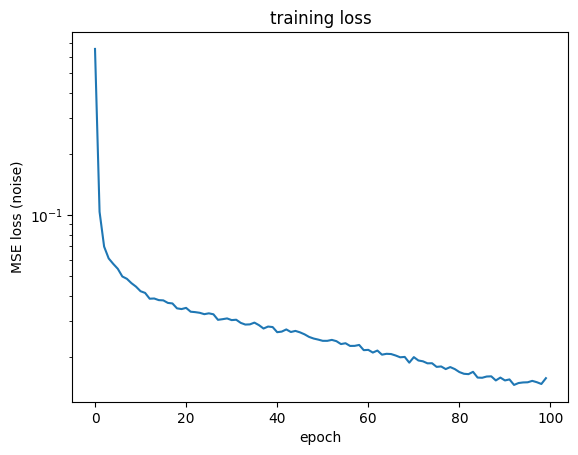

In [7]:
from diffusers import DDPMScheduler
from diffusers.optimization import get_scheduler

NUM_DIFFUSION_STEPS = 100
NUM_EPOCHS = 100

noise_scheduler = DDPMScheduler(
    num_train_timesteps=NUM_DIFFUSION_STEPS,
    beta_schedule="squaredcos_cap_v2",  # cosine 스케줄
    clip_sample=True,                   # 생성 결과를 [-1, 1]로 자름 (정규화 범위와 일치)
    prediction_type="epsilon",          # 모델이 노이즈를 예측 !!!!!!!!!!!!!!
)


class EMA: #모델 가중치의 이동 평균을 따로 저장
    """가중치 지수이동평균. 학습 초반엔 decay를 작게, 점점 0.9999에 가깝게."""
    def __init__(self, model, max_decay=0.9999):
        self.model = copy.deepcopy(model).eval()
        for p in self.model.parameters():
            p.requires_grad_(False)
        self.max_decay, self.step = max_decay, 0

    @torch.no_grad()
    def update(self, model):
        self.step += 1
        decay = min(self.max_decay, (1 + self.step) / (10 + self.step))
        for p_ema, p in zip(self.model.parameters(), model.parameters()):
            p_ema.mul_(decay).add_(p.detach(), alpha=1 - decay)


ema = EMA(model)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-6)
lr_scheduler = get_scheduler(
    "cosine", optimizer=optimizer,
    num_warmup_steps=500, num_training_steps=len(dataloader) * NUM_EPOCHS,
)

losses = []
for epoch in (pbar := tqdm(range(NUM_EPOCHS), desc="epoch")):
    epoch_loss = []
    for batch in dataloader:
        obs = batch["obs"].to(device)            # (B, 2, 5)
        a0 = batch["action"].to(device)          # (B, 16, 2)
        B = a0.shape[0]
        cond = obs.flatten(start_dim=1)          # (B, 10)

        noise = torch.randn_like(a0)
        k = torch.randint(0, NUM_DIFFUSION_STEPS, (B,), device=device)
        a_noisy = noise_scheduler.add_noise(a0, noise, k)

        pred = model(a_noisy, k, global_cond=cond)
        loss = F.mse_loss(pred, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()
        ema.update(model)
        epoch_loss.append(loss.item())
    losses.append(np.mean(epoch_loss))
    pbar.set_postfix(loss=f"{losses[-1]:.4f}")

torch.save({"ema": ema.model.state_dict(), "stats": stats}, "diffusion_policy_pusht.pt")

plt.plot(losses); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE loss (noise)")
plt.title("training loss"); plt.show()

MSE loss 예측한 노이즈와 실제 노이즈의 차이

Q: MSE인데 왜 평균 문제가 안생기는 것인가?

A: 행동이 아니라 노이즈를 맞히고, 실행할 때는 랜덤 노이즈에서 출발하니까 매번 하나의 정답을 고른다.

## 5. 행동 생성: 노이즈에서 시작해 디노이징

추론할 때는 순수 노이즈 $A^K$에서 시작해서 모델이 예측한 노이즈를 조금씩 빼며 $A^0$까지 내려갑니다.

$A^{k-1} = \alpha\,(A^k - \gamma\,\epsilon_\theta(A^k, k, O)) + \sigma z$  (`scheduler.step`)

중간 과정을 저장해 두면 **노이즈가 점점 그럴듯한 궤적으로 바뀌는 모습**을 볼 수 있습니다.

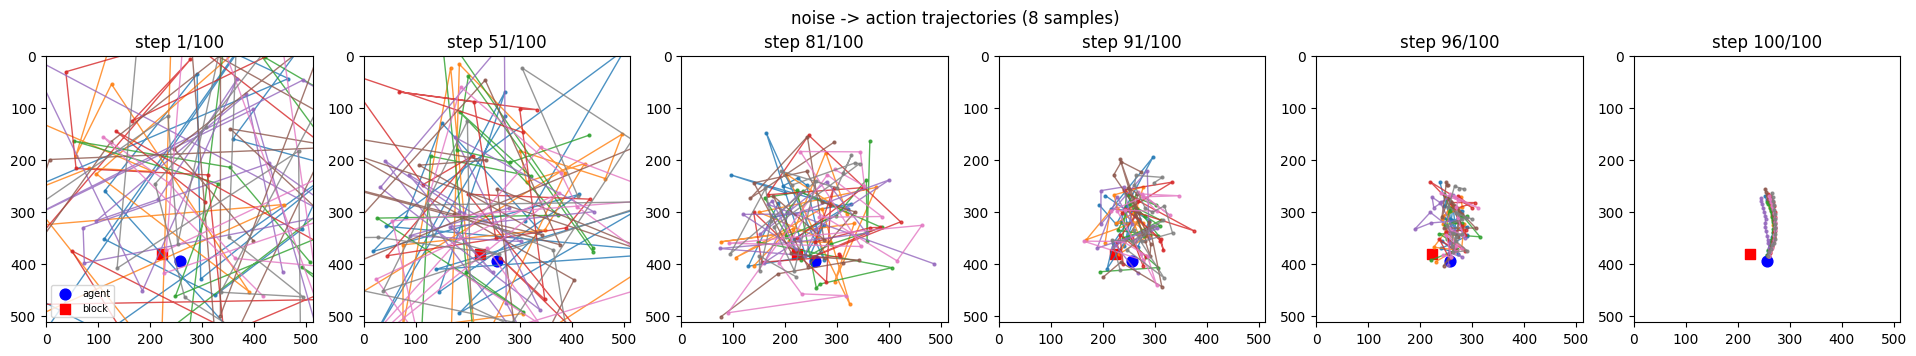

In [8]:
ema_model = ema.model

@torch.no_grad()
def sample_actions(obs_seq, n_samples=1, return_history=False):
    """obs_seq: (2, 5) 원래 좌표의 관측 → (n_samples, 16, 2) 원래 좌표의 행동"""
    nobs = normalize(np.asarray(obs_seq, dtype=np.float32), stats["state"])
    cond = torch.from_numpy(nobs).float().flatten().unsqueeze(0).repeat(n_samples, 1).to(device)

    a = torch.randn(n_samples, PRED_HORIZON, ACTION_DIM, device=device)  # A^K
    noise_scheduler.set_timesteps(NUM_DIFFUSION_STEPS)
    history = []
    for k in noise_scheduler.timesteps:
        eps = ema_model(a, k, global_cond=cond)
        a = noise_scheduler.step(eps, k, a).prev_sample
        if return_history:
            history.append(unnormalize(a.cpu().numpy(), stats["action"]))

    a = unnormalize(a.cpu().numpy(), stats["action"])
    return (a, history) if return_history else a


# 데이터셋의 한 시점을 골라 8개 샘플을 생성해 본다
t0 = 50
obs_seq = states[t0 - 1:t0 + 1]
samples, history = sample_actions(obs_seq, n_samples=8, return_history=True)

show_steps = [0, 50, 80, 90, 95, 99]   # 디노이징 진행 단계
fig, axes = plt.subplots(1, len(show_steps), figsize=(3.2 * len(show_steps), 3.4))
for ax, s in zip(axes, show_steps):
    for traj in history[s]:
        ax.plot(traj[:, 0], traj[:, 1], "-o", ms=2, lw=1, alpha=0.8)
    ax.scatter(*obs_seq[-1, :2], c="blue", s=60, marker="o", label="agent")
    ax.scatter(*obs_seq[-1, 2:4], c="red", s=60, marker="s", label="block")
    ax.set_xlim(0, 512); ax.set_ylim(512, 0); ax.set_aspect("equal")
    ax.set_title(f"step {s + 1}/{NUM_DIFFUSION_STEPS}")
axes[0].legend(fontsize=7)
plt.suptitle("noise -> action trajectories (8 samples)")
plt.tight_layout(); plt.show()

## 6. 시뮬레이터에서 평가

`gym-pusht` 환경에서 정책을 돌립니다. **관측 2개 → 16스텝 예측 → 앞 8스텝 실행 → 반복**.

- **coverage**: 블록이 목표 T 영역을 덮은 비율 (0~1). 에피소드 중 최댓값을 점수로 봅니다.
- **success**: coverage가 95% 이상이면 성공

In [9]:
import gymnasium as gym
import gym_pusht
import mediapy

def run_episode(seed, max_steps=300, record=False):
    env = gym.make("gym_pusht/PushT-v0", obs_type="state", render_mode="rgb_array")
    obs, info = env.reset(seed=seed)
    obs_deque = collections.deque([obs] * OBS_HORIZON, maxlen=OBS_HORIZON)
    frames = [env.render()] if record else []
    max_cov, success, step = 0.0, False, 0

    while step < max_steps and not success:
        action_seq = sample_actions(np.stack(obs_deque))[0]                    # (16, 2)
        exec_actions = action_seq[OBS_HORIZON - 1: OBS_HORIZON - 1 + ACTION_HORIZON]  # 8개
        for act in exec_actions:
            obs, reward, terminated, truncated, info = env.step(act)
            obs_deque.append(obs)
            max_cov = max(max_cov, reward)
            step += 1
            if record:
                frames.append(env.render())
            if info["is_success"] or terminated:
                success = True
                break
            if step >= max_steps or truncated:
                break
    env.close()
    return max_cov, success, frames


cov, succ, frames = run_episode(seed=100000, record=True)
print(f"max coverage = {cov:.3f}, success = {succ}")
mediapy.show_video(frames, fps=10)

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


max coverage = 0.987, success = False


This browser does not support the video tag.


여러 초기 상태에서 평균 성능을 측정합니다.

In [10]:
N_EVAL = 10
results = [run_episode(seed=100000 + i)[:2] for i in tqdm(range(N_EVAL))]
covs = np.array([c for c, _ in results])
succs = np.array([s for _, s in results])
print(f"평균 max coverage: {covs.mean():.3f}")
print(f"성공률: {succs.mean() * 100:.0f}%  ({succs.sum()}/{N_EVAL})")

  0%|          | 0/10 [00:00<?, ?it/s]

평균 max coverage: 0.946
성공률: 40%  (4/10)


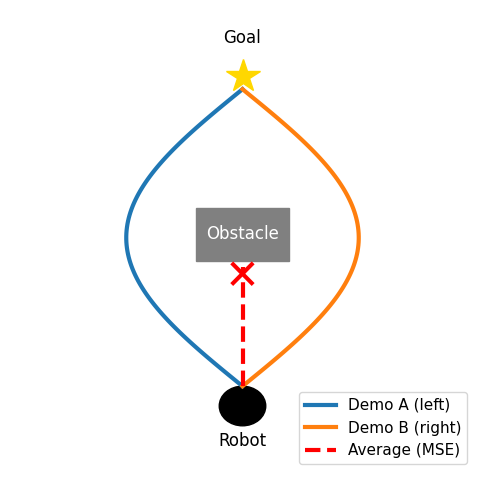

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

fig, ax = plt.subplots(figsize=(6, 6))
ax.add_patch(Rectangle((-0.6, 2.2), 1.2, 0.8, color="gray"))          # 장애물
ax.text(0, 2.6, "Obstacle", ha="center", va="center", color="white", fontsize=12)
ax.add_patch(Circle((0, 0), 0.3, color="black"))                     # 로봇
ax.text(0, -0.6, "Robot", ha="center", fontsize=12)
ax.plot(0, 5, marker="*", markersize=25, color="gold")               # 목표
ax.text(0, 5.5, "Goal", ha="center", fontsize=12)

y = np.linspace(0.3, 4.8, 100)
bump = 1.5 * np.sin(np.pi * (y - 0.3) / 4.5)
ax.plot(-bump, y, color="tab:blue", lw=3, label="Demo A (left)")
ax.plot(bump, y, color="tab:orange", lw=3, label="Demo B (right)")
ax.plot([0, 0], [0.3, 2.1], color="red", lw=3, ls="--", label="Average (MSE)")
ax.text(0, 1.95, "✕", ha="center", va="center", color="red", fontsize=30, fontweight="bold")

ax.set_xlim(-3, 3); ax.set_ylim(-1, 6); ax.axis("off")
ax.legend(loc="lower right", fontsize=11)
plt.savefig("slide4_multimodal.png", dpi=200, bbox_inches="tight", transparent=True)
plt.show()

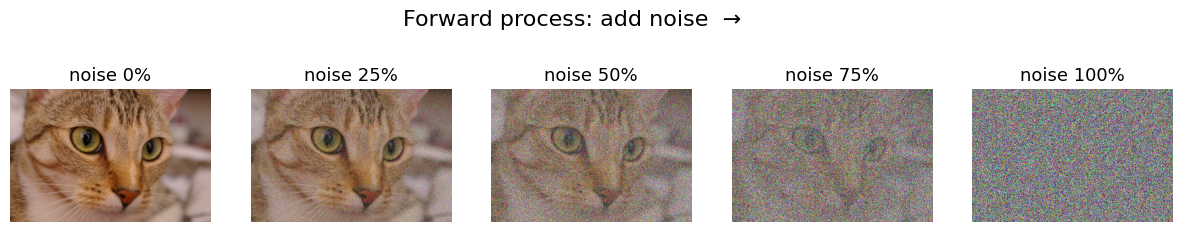

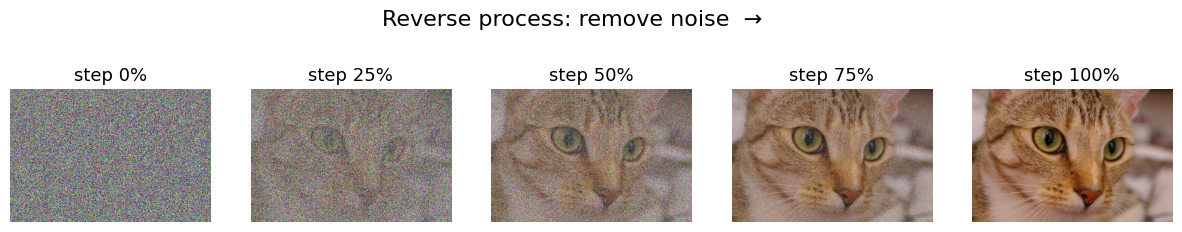

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = data.chelsea() / 255.0          # Colab 기본 내장 고양이 사진
rng = np.random.default_rng(0)
noise = rng.random(img.shape)
levels = [0, 0.25, 0.5, 0.75, 1.0]

def noisy(a):
    return np.clip((1 - a) * img + a * noise, 0, 1)

# Forward: 이미지 → 노이즈
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, a in zip(axes, levels):
    ax.imshow(noisy(a)); ax.axis("off")
    ax.set_title(f"noise {int(a*100)}%", fontsize=13)
fig.suptitle("Forward process: add noise  →", fontsize=16)
plt.savefig("slide6_forward.png", dpi=200, bbox_inches="tight", transparent=True)
plt.show()

# Reverse: 노이즈 → 이미지
fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for ax, a in zip(axes, levels[::-1]):
    ax.imshow(noisy(a)); ax.axis("off")
    ax.set_title(f"step {int((1-a)*100)}%", fontsize=13)
fig.suptitle("Reverse process: remove noise  →", fontsize=16)
plt.savefig("slide6_reverse.png", dpi=200, bbox_inches="tight", transparent=True)
plt.show()

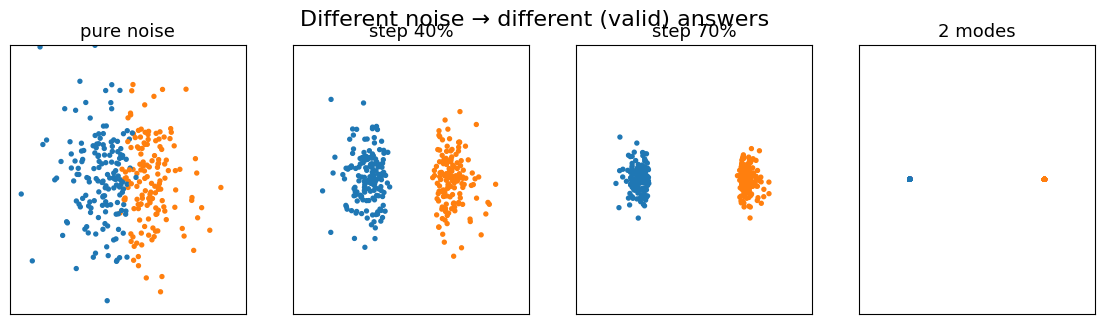

In [13]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
start = rng.standard_normal((300, 2))
left = start[:, 0] < 0
target = np.where(left[:, None], [-2.0, 0.0], [2.0, 0.0])
colors = np.where(left, "tab:blue", "tab:orange")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, t in zip(axes, [0, 0.4, 0.7, 1.0]):
    p = (1 - t) * start + t * target + 0.15 * (1 - t) * rng.standard_normal((300, 2))
    ax.scatter(p[:, 0], p[:, 1], s=8, c=colors)
    ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3, 3)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title("pure noise" if t == 0 else ("2 modes" if t == 1 else f"step {int(t*100)}%"), fontsize=13)
fig.suptitle("Different noise → different (valid) answers", fontsize=16)
plt.savefig("slide7_modes.png", dpi=200, bbox_inches="tight", transparent=True)
plt.show()

In [14]:
import collections
import numpy as np
import torch
import imageio

def run_rollout(seed, max_steps=200, diffusion_iters=None):
    """seed 하나로 에피소드를 돌리고 (영상 프레임, 최고 점수)를 돌려줌"""
    if diffusion_iters is None:
        diffusion_iters = num_diffusion_iters

    env = PushTImageEnv()
    env.seed(seed)
    obs, info = env.reset()
    obs_deque = collections.deque([obs] * obs_horizon, maxlen=obs_horizon)
    imgs = [env.render(mode='rgb_array')]
    rewards = []
    done = False
    step_idx = 0

    while not done:
        images = np.stack([x['image'] for x in obs_deque])
        agent_poses = np.stack([x['agent_pos'] for x in obs_deque])
        nagent_poses = normalize_data(agent_poses, stats=stats['agent_pos'])

        nimages = torch.from_numpy(images).to(device, dtype=torch.float32)
        nagent_poses = torch.from_numpy(nagent_poses).to(device, dtype=torch.float32)

        with torch.no_grad():
            image_features = ema_nets['vision_encoder'](nimages)
            obs_features = torch.cat([image_features, nagent_poses], dim=-1)
            obs_cond = obs_features.unsqueeze(0).flatten(start_dim=1)

            naction = torch.randn((1, pred_horizon, action_dim), device=device)
            noise_scheduler.set_timesteps(diffusion_iters)
            for k in noise_scheduler.timesteps:
                noise_pred = ema_nets['noise_pred_net'](
                    sample=naction, timestep=k, global_cond=obs_cond)
                naction = noise_scheduler.step(
                    model_output=noise_pred, timestep=k, sample=naction).prev_sample

        naction = naction.detach().cpu().numpy()[0]
        action_pred = unnormalize_data(naction, stats=stats['action'])
        start = obs_horizon - 1
        action = action_pred[start:start + action_horizon, :]

        for a in action:
            obs, reward, done, _, info = env.step(a)
            obs_deque.append(obs)
            rewards.append(reward)
            imgs.append(env.render(mode='rgb_array'))
            step_idx += 1
            if step_idx > max_steps:
                done = True
            if done:
                break

    return imgs, max(rewards)

In [18]:
import inspect
print("signature:", inspect.signature(run_episode))
print(inspect.getsource(run_episode)[-500:])   # 함수 끝부분 (return 확인용)
print("results:", type(results), len(results))
print("covs:", covs)
print("succs:", succs)
print("horizons:", OBS_HORIZON, PRED_HORIZON, ACTION_HORIZON, "| OBS_DIM:", OBS_DIM)

signature: (seed, max_steps=300, record=False)
N]  # 8개
        for act in exec_actions:
            obs, reward, terminated, truncated, info = env.step(act)
            obs_deque.append(obs)
            max_cov = max(max_cov, reward)
            step += 1
            if record:
                frames.append(env.render())
            if info["is_success"] or terminated:
                success = True
                break
            if step >= max_steps or truncated:
                break
    env.close()
    return max_cov, success, frames

results: <class 'list'> 0
covs: [0.57982605 0.98462204 1.         1.         0.98325557 0.95361028
 1.         0.97933707 0.98008642 1.        ]
succs: [False False  True  True False False  True False False  True]
horizons: 2 16 8 | OBS_DIM: 5


In [19]:
import imageio
import numpy as np
from google.colab import files

rec = []
for seed in range(10):
    cov, succ, frames = run_episode(seed, record=True)
    rec.append((seed, float(cov), succ, frames))
    print(f"seed {seed}: score {cov:.3f}, success {succ}")

succ_eps = [r for r in rec if r[2]]
fail_eps = sorted([r for r in rec if not r[2]], key=lambda r: r[1])

if succ_eps:
    s = succ_eps[0]
    imageio.mimsave("rollout_success.mp4", s[3], fps=10)
    print("성공 영상: seed", s[0])
    files.download("rollout_success.mp4")

if fail_eps:
    worst = fail_eps[0]      # 점수가 가장 낮은 실패
    near = fail_eps[-1]      # 아깝게 실패 (0.98 같은 것)
    imageio.mimsave("rollout_fail_worst.mp4", worst[3], fps=10)
    imageio.mimsave("rollout_fail_near.mp4", near[3], fps=10)
    print("크게 실패: seed", worst[0], "/ 아깝게 실패: seed", near[0])
    files.download("rollout_fail_worst.mp4")
    files.download("rollout_fail_near.mp4")

print("성공률:", np.mean([r[2] for r in rec]), "| 평균 score:", np.mean([r[1] for r in rec]))

seed 0: score 1.000, success True
seed 1: score 0.590, success False
seed 2: score 1.000, success True
seed 3: score 1.000, success True
seed 4: score 1.000, success True
seed 5: score 1.000, success True
seed 6: score 1.000, success True
seed 7: score 0.898, success False
seed 8: score 1.000, success True
seed 9: score 1.000, success True


성공 영상: seed 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

크게 실패: seed 1 / 아깝게 실패: seed 7


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

성공률: 0.8 | 평균 score: 0.9487474153654049
